In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
df.to_csv('student_data.csv', index=False)


    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


In [2]:
df = df[df['study_hours'] != 50]
print(df)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
94     4.215784   86.731809      75.355232    49.095682
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627

[99 rows x 4 columns]


In [3]:
df.loc[df['attendance'] < 0, 'attendance'] = np.nan
df['study_hours'] = df['study_hours'].fillna( df['study_hours'].mean())
df['attendance'] = df['attendance'].fillna(df['attendance'].mean())
print(df)

    study_hours  attendance  previous_mark  final_score
0      4.737399   70.846293      75.366810    35.178989
1      4.737399   80.793547      78.411768    39.481248
2      4.737399   81.572855      86.245769    48.605167
3      4.737399   76.977227      85.807031    47.329456
4      4.737399   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
94     4.215784   86.731809      75.355232    49.095682
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227   85.338288      82.192932    44.045627

[99 rows x 4 columns]


Part A — Inspect and Clean
1. Identify and handle the outlier

The value of 50 hours in study_hours is an outlier because studying for 50 hours in a single day is unrealistic. I chose to remove the entire row because the value is likely invalid and could distort the statistical analysis.

I replaced the missing values in study_hours with the mean of the available study-hour values. I chose mean imputation because it allows me to keep the dataset rows instead of deleting students with missing information. This helps preserve the size of the dataset and allows further statistical analysis to be performed without missing values in this column.

I replaced the negative attendance value of -10 with the mean attendance value because negative attendance is invalid in this dataset. Attendance represents a percentage, so a negative value is not meaningful. I treated it as an invalid value and replaced it with the mean of the valid attendance values to avoid allowing an incorrect value to distort the analysis.

2. Feature matrix and target variable

The numerical columns are study_hours, attendance, previous_mark, and final_score. The target variable is final_score, because it is the value we want to predict. The feature matrix contains study_hours, attendance, and previous_mark.The feature matrix has a shape of (99, 3).

In [4]:
print("column_1_mean:", np.mean(df['study_hours']))
print("column_2_mean:", np.mean(df['attendance']))
print("column_3_mean:", np.mean(df['previous_mark']))
print("column_4_mean:", np.mean(df['final_score']))

column_1_mean: 4.737399085576119
column_2_mean: 85.3382877841201
column_3_mean: 70.88787825274562
column_4_mean: 42.654355460561455


In [5]:
print("column_1_median:", np.median(df['study_hours']))
print("column_2_median:", np.median(df['attendance']))
print("column_3_median:", np.median(df['previous_mark']))
print("column_4_median:", np.median(df['final_score']))

column_1_median: 4.737399085576119
column_2_median: 85.99651365087641
column_3_median: 71.22811209079484
column_4_median: 42.673003362824986


In [6]:
print("column_1__standard_deviation:", np.std(df['study_hours']))
print("column_2__standard_deviation:", np.std(df['attendance']))
print("column_3__standard_deviation:", np.std(df['previous_mark']))
print("column_4__standard_deviation:", np.std(df['final_score']))


column_1__standard_deviation: 1.7747691345960293
column_2__standard_deviation: 9.463742370590866
column_3__standard_deviation: 16.24171979212189
column_4__standard_deviation: 6.075171983171862


Part B — Summarize

2. Three observations in plain English

The mean and median of final_score are almost equal, at approximately 42.65 and 42.67. This suggests that the distribution of final scores is fairly balanced around its center.

previous_mark has the largest standard deviation, approximately 16.24, indicating that students' previous marks vary more than their study hours, attendance, or final scores.

The standard deviation of attendance is approximately 9.46, suggesting some variation in attendance among students, although most values are relatively close to the mean of 85.34.

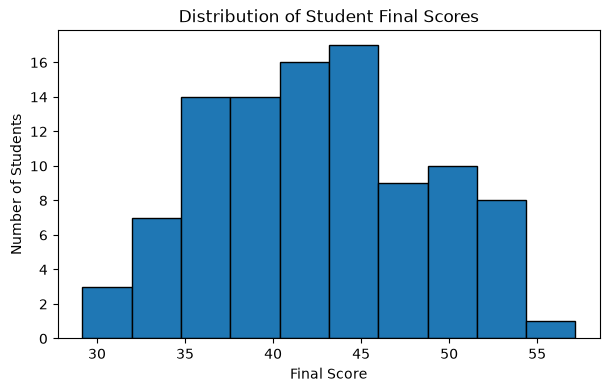

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.hist(df['final_score'], bins=10, edgecolor='black')

plt.xlabel('Final Score')
plt.ylabel('Number of Students')
plt.title('Distribution of Student Final Scores')

plt.show()

Part C — Visualize

1. Histogram of final scores

The histogram shows that most students' final scores fall approximately between 35 and 50. The highest bars are around 40–45, indicating that this is the most common score range. Very few students have scores at the extreme ends, such as below 30 or above 55.

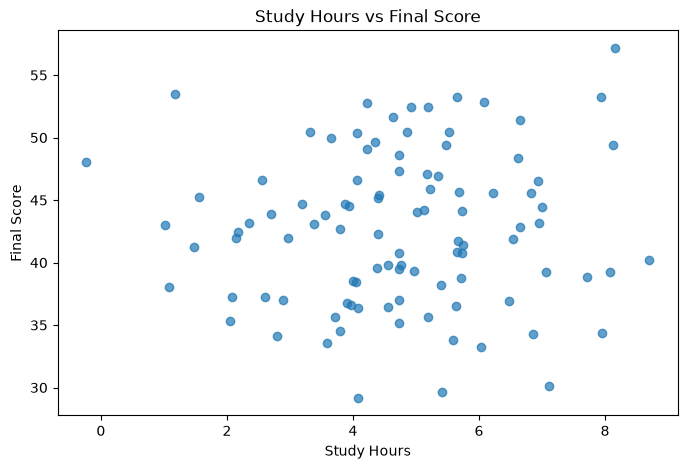

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(df['study_hours'], df['final_score'], alpha=0.7)
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.title('Study Hours vs Final Score')

plt.show()

2. Scatter plot of study hours versus final score

The scatter plot shows a weak positive relationship, with considerable variation. Some students who study more hours receive higher scores, but others receive lower scores despite studying for more hours. Therefore, study hours alone do not explain students' final scores, and other factors such as attendance and previous academic performance may also contribute.

In [10]:
correlation = df['study_hours'].corr(df['final_score'])

print("Pearson correlation coefficient:", correlation)

Pearson correlation coefficient: 0.05010151148096447


Part D — Correlation and Causality

2. Correlation and causality

No, correlation does not guarantee that a student who studies for 10 hours will receive a specific score. Correlation describes the relationship between two variables but does not guarantee an exact outcome or prove that one variable causes the other.

In [11]:
features = ['study_hours', 'attendance', 'previous_mark']
x = df[features].iloc[10].to_numpy()
print("Student vector x:", x)
w = np.array([0.5, 0.2, 0.4])
b = 5
print("Weight vector w:", w)
print("Bias b:", b)
dot_product = np.dot(w, x)
y = dot_product + b
print("Dot product:", dot_product)
print("y =", y)

Student vector x: [ 4.07316461 65.81228785 78.56335766]
Weight vector w: [0.5 0.2 0.4]
Bias b: 5
Dot product: 46.62438294074846
y = 51.62438294074846


Part E — Vectors and Dot Product

4. Meaning of weights and bias

The weight vector represents the contribution assigned to each input feature when calculating a predicted score. Each weight is multiplied by its corresponding feature value.

The bias is a constant added to the result. It allows the model to adjust its prediction independently of the input values. Together, the weights and bias form a simple linear prediction model.

In [12]:
df['study_hours_scaled'] = (
    df['study_hours'] - df['study_hours'].mean()
) / df['study_hours'].std()

df['previous_mark_scaled'] = (
    df['previous_mark'] - df['previous_mark'].mean()
) / df['previous_mark'].std()

print(df[['study_hours', 'study_hours_scaled',
          'previous_mark', 'previous_mark_scaled']])

    study_hours  study_hours_scaled  previous_mark  previous_mark_scaled
0      4.737399            0.000000      75.366810              0.274371
1      4.737399            0.000000      78.411768              0.460899
2      4.737399            0.000000      86.245769              0.940795
3      4.737399            0.000000      85.807031              0.913919
4      4.737399            0.000000      49.334959             -1.320291
..          ...                 ...            ...                   ...
94     4.215784           -0.292418      75.355232              0.273662
95     2.072970           -1.493681      59.606356             -0.691084
96     5.592241            0.479225      83.493998              0.772227
97     5.522111            0.439910      74.609493              0.227979
98     5.010227            0.152947      82.192932              0.692526

[99 rows x 4 columns]


Part F — Scaling

2. Why scaling is important

K-Nearest Neighbors (KNN) uses distances to identify the closest data points. In this dataset, previous_mark has a standard deviation of approximately 16.24, while study_hours has a standard deviation of approximately 1.77. Without scaling, differences in previous marks could dominate the distance calculation because their numerical range is much larger.

Standardization puts both features on a comparable scale, helping prevent one feature from dominating simply because its numbers are larger.